In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import imodex_miri_postprocess_pipeline as imp #homemade pipeline
from scipy import ndimage
import math

In [2]:
class Constantes():
    def __init__(self,pixscale, filt, v3i):
        self.pixscale = pixscale # arcsec
        self.filt     = filt
        self.v3i      = v3i      #header[1]['V3I_YANG']  # 4.83544897 #4QPM rotation
        if filt == 'F1065C': self.lam = 10.65e-6 #central wavelenght for each filter
        if filt == 'F1140C': self.lam = 11.4e-6
        if filt == 'F1550C': self.lam = 15.5e-6
        if filt == 'F2300C': self.lam = 23.0e-6
    def addition(xdim, ydim, dr, npsf):
        self.dr   = dr
        self.npsf = npsf
        self.xdim = xdim
        self.ydim = ydim

def coro_attenuation_measure(path_sim, path_save):

    file  = fits.open(path_sim+filename+".fits")
    header = file[0].header
    
    cst.npsf = header['naxis3']
    cst.xdim = header['naxis1'] #int(np.sqrt(cst.npsf)) # 
    cst.ydim = header['naxis2'] #int(np.sqrt(cst.npsf)) # 
    psf_coro = file[0].data
    print('initialization : npsf='+str(cst.npsf)+' xdim='+str(cst.xdim)+' ydim='+str(cst.ydim))
    max_psf   = np.zeros((cst.ydim+1,cst.xdim+1), dtype='float32')
    sum_psf   = np.zeros((cst.ydim+1,cst.xdim+1), dtype='float32')
    sum_img   = np.zeros((cst.ydim+1,cst.xdim+1), dtype='float32')
    file.close()
    
    Y, X     = np.ogrid[:cst.xdim, :cst.ydim] #grid for mask
    mask_map = np.ndarray([cst.npsf,cst.ydim,cst.xdim])*0.
    for i in range(cst.npsf):
        cpsfx = i//(cst.xdim+1) #centre de la PSF en X
        cpsfy = i%(cst.xdim+1)  #centre de la PSF en Y
        mask = np.sqrt((X -cpsfx+0.5)**2 + (Y -cpsfy+0.5)**2)
        mask_map[i,:,:] = psf_coro[i,:,:] * (mask <= cst.dr)
        sum_psf[cpsfy,cpsfx] = np.nansum(psf_coro[i,:,:] * (mask <= cst.dr))
        sum_img[cpsfy,cpsfx] = np.nansum(psf_coro[i,:,:])
        max_psf[cpsfy,cpsfx] = np.max(psf_coro[i,:,:])
        
    f_co = sum_img/sum_psf    

    max_psf /= np.max(max_psf)
    sum_psf /= np.max(sum_psf)
    return f_co, max_psf, sum_psf, mask_map



def coro_attenuation_plot(max_psf, sum_psf, path_save):

#### trouver comment flip les cartes de transmission ???????????????

    transmi_max = max_psf #np.reshape(max_psf,(cst.ydim+1,cst.xdim+1)) 
    transmi_sum = sum_psf #np.reshape(sum_psf,(cst.ydim+1,cst.xdim+1))


    #### difference between both method       
    imp.save_fits(transmi_sum-transmi_max,path_save+cst.filt+'_diff_transmission_sum-max.fits')
    
    scale=[(cst.xdim/2.+0.5)*cst.pixscale, -1*(cst.xdim/2.+0.5)*cst.pixscale, -1*(cst.ydim/2.+0.5)*cst.pixscale, (cst.ydim/2.+0.5)*cst.pixscale]
    fig1 = plt.figure(figsize=(8,8))
    tmp = plt.imshow(transmi_sum-transmi_max,origin='lower',cmap='seismic',interpolation='none',vmin=-0.10,vmax=0.10,extent=scale)
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('Transmission difference',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    plt.show()
    fig1.savefig(path_save+cst.filt+'_diff_transmission_sum-max.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)


    fig1 = plt.figure(figsize=(8,8))
    tmp = plt.imshow(transmi_max,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('Transmission - PSF max',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    plt.show()
    fig1.savefig(path_save+cst.filt+'_transmission_max.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)    

    fig1 = plt.figure(figsize=(8,8))
    tmp = plt.imshow(transmi_sum,origin='lower',cmap='inferno',interpolation='none',vmin=0.0,vmax=1,extent=scale)
    cax  = fig1.add_axes([0.9, 0.125, 0.02, 0.76])
    cbar = fig1.colorbar(tmp, cax=cax, orientation='vertical')
    cbar.set_label('Transmission - PSF sum',fontsize=10)
    cbar.ax.tick_params(length=2,pad=1,labelsize=10)
    plt.show()
    fig1.savefig(path_save+cst.filt+'_transmission_sum.pdf',format='pdf',bbox_inches='tight')
    plt.close(fig1)  


    imp.save_fits(transmi_sum,path_save+cst.filt+'_transmi_sum.fits')
    imp.save_fits(transmi_max,path_save+cst.filt+'_transmi_max.fits')
    
    
def correction_factor_open_phot(path_sim, psfname, out_f_co):
    #path_sim  = '/home/cperrot/Work/raw/JWST/STPSF/F1140C_PSF/'
    psf       = fits.open(path_sim+psfname+".fits")[0].data

    Y, X = np.ogrid[:cst.ydim, :cst.xdim]

    mask = np.sqrt((X - cst.xdim//2 +0.5)**2 + (Y - cst.ydim//2 +0.5)**2)
    mask = mask <= cst.dr

    return np.sum(psf)/np.sum(psf*mask)

initialization : npsf=40401 xdim=200 ydim=200


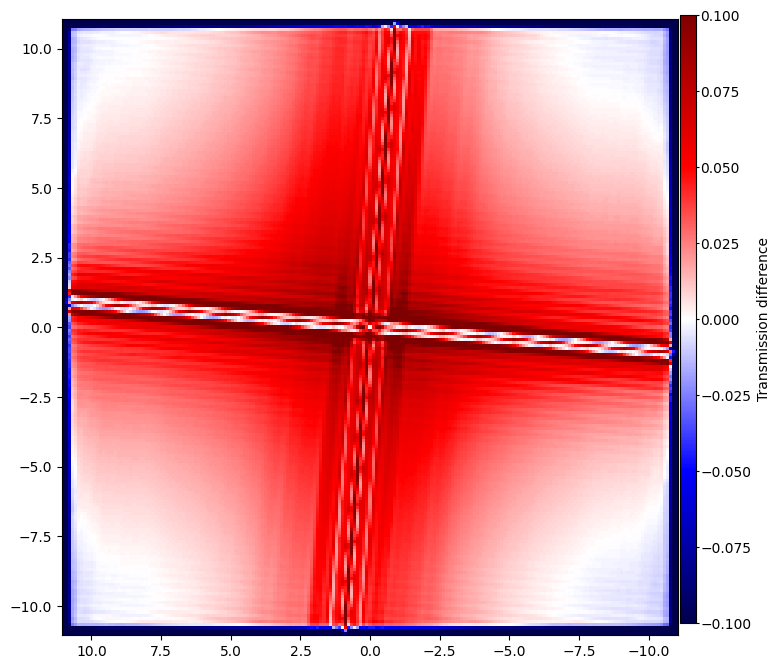

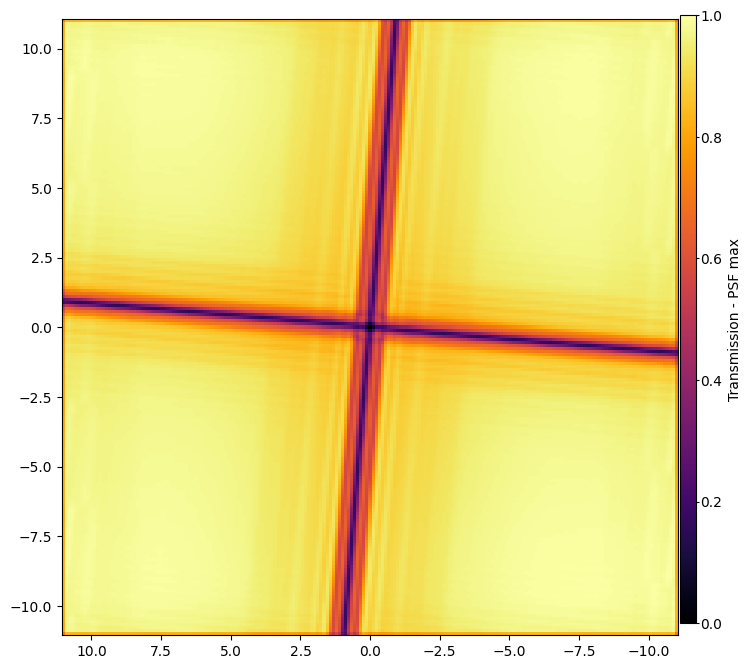

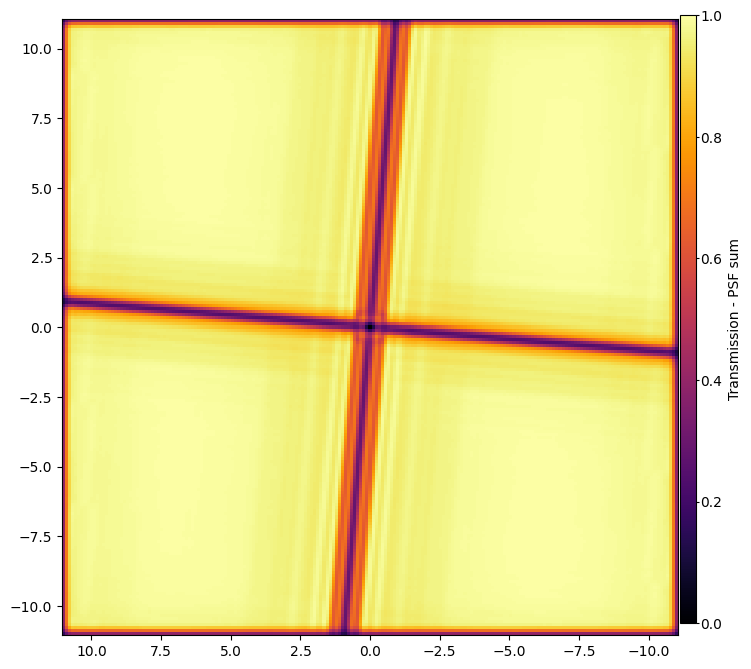

facteur de correction a F1065C :  2.0790243339681975


In [3]:
path_sim  = '/home/cperrot/Work/raw/JWST/STPSF/F1065C_PSF/'
path_save = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
filename  = 'F1065C_PSF_cube_save'
psfname   = 'F1065C_PSF_PSF_without_coro'
filt      = 'F1065C'

#constant
coef_dr   = 1.5
cst = Constantes(0.110, filt, 4.83544897)
cst.dr = coef_dr*cst.lam/6.5*180.*3600./np.pi/cst.pixscale # taille en pixel de COEF_DR lambda/D


out_f_co, out_max_psf, out_sum_psf, mask_map = coro_attenuation_measure(path_sim, path_save)
coro_attenuation_plot(out_max_psf, out_sum_psf, path_save)
fact_corr = correction_factor_open_phot(path_sim, psfname, out_f_co)
print("facteur de correction a "+filt+" : ", fact_corr)

initialization : npsf=40401 xdim=200 ydim=200


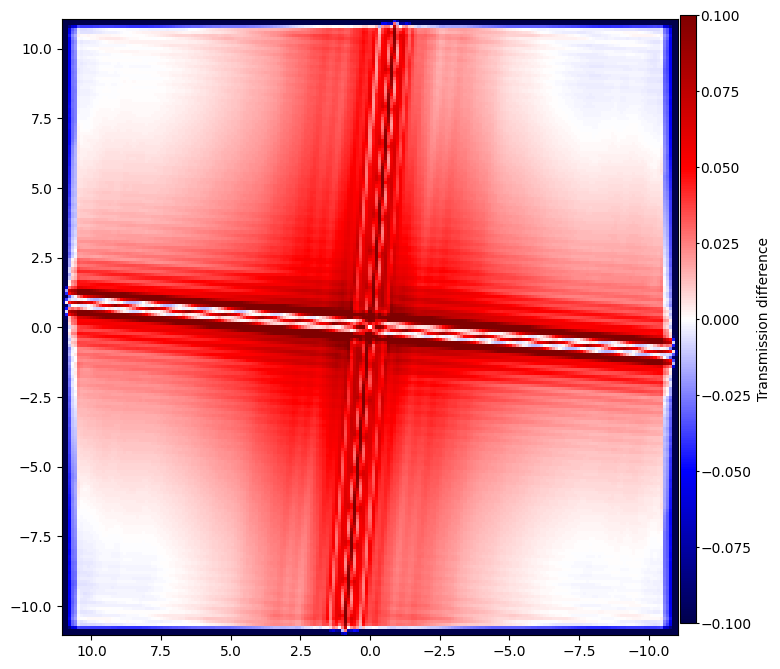

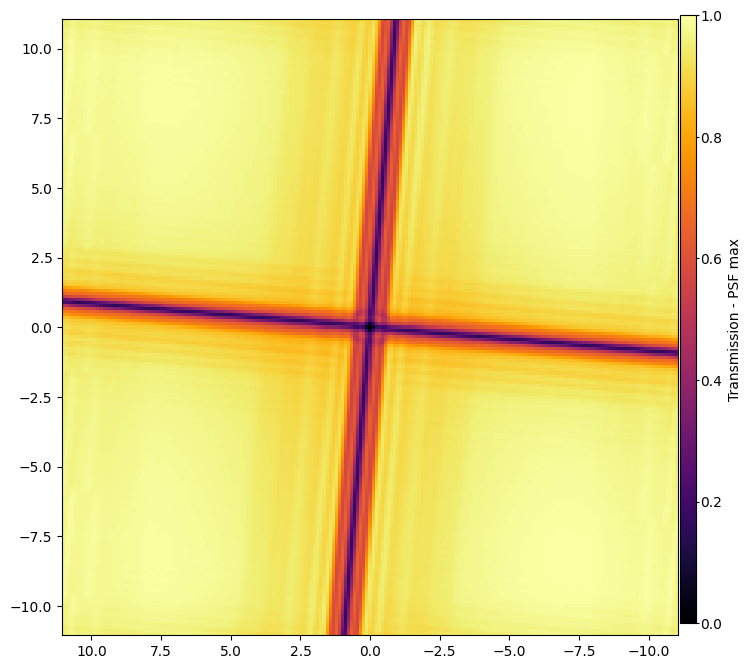

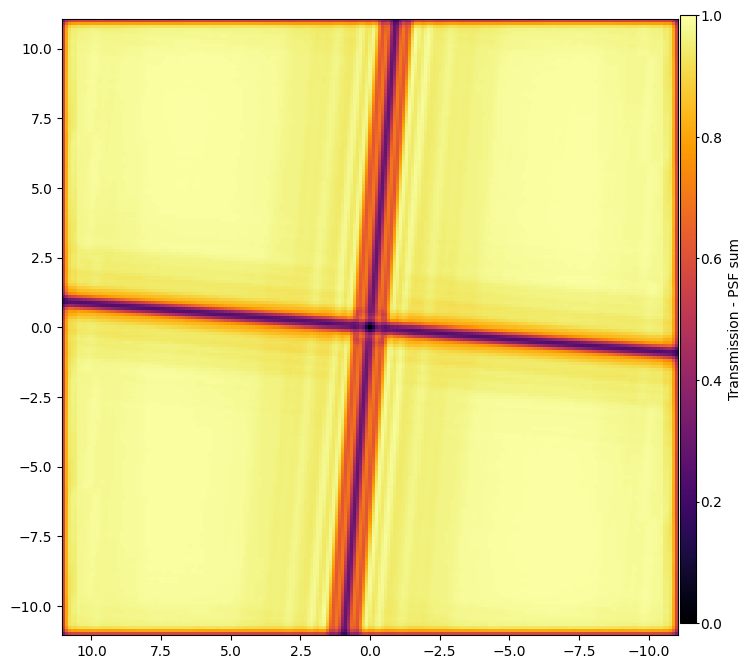

facteur de correction a F1140C :  2.0887366235130878


In [4]:
path_sim  = '/home/cperrot/Work/raw/JWST/STPSF/F1140C_PSF/'
path_save = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
filename  = 'F1140C_PSF_cube_save'
psfname   = 'F1140C_PSF_PSF_without_coro'
filt      = 'F1140C'

#constant
coef_dr   = 1.5
cst = Constantes(0.110, filt, 4.83544897)
cst.dr = coef_dr*cst.lam/6.5*180.*3600./np.pi/cst.pixscale # taille en pixel de COEF_DR lambda/D


out_f_co, out_max_psf, out_sum_psf, mask_map = coro_attenuation_measure(path_sim, path_save)
coro_attenuation_plot(out_max_psf, out_sum_psf, path_save)
fact_corr = correction_factor_open_phot(path_sim, psfname, out_f_co)
print("facteur de correction a "+filt+" : ", fact_corr)

initialization : npsf=40401 xdim=200 ydim=200


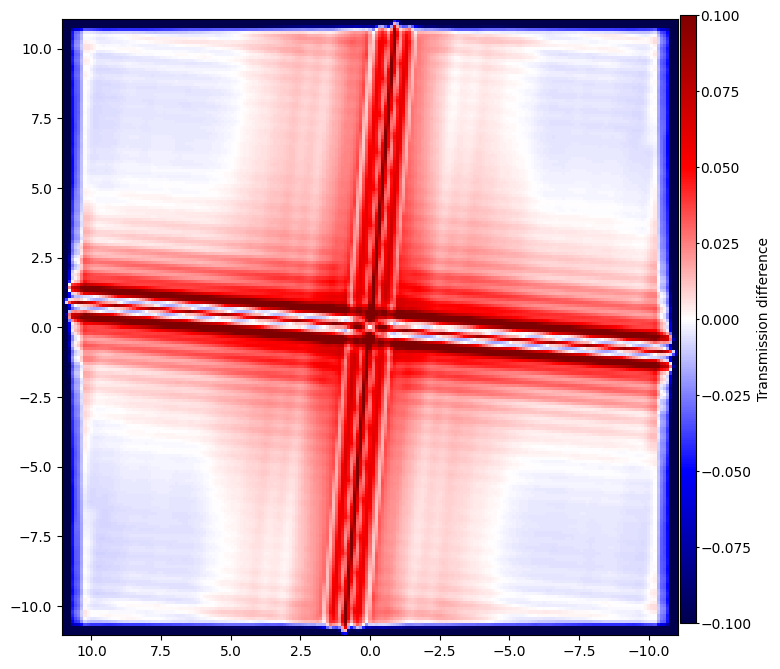

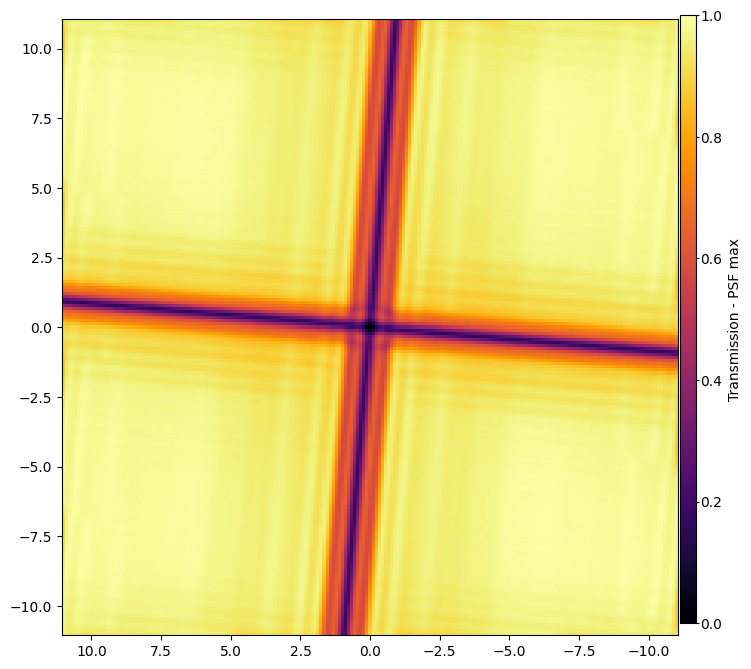

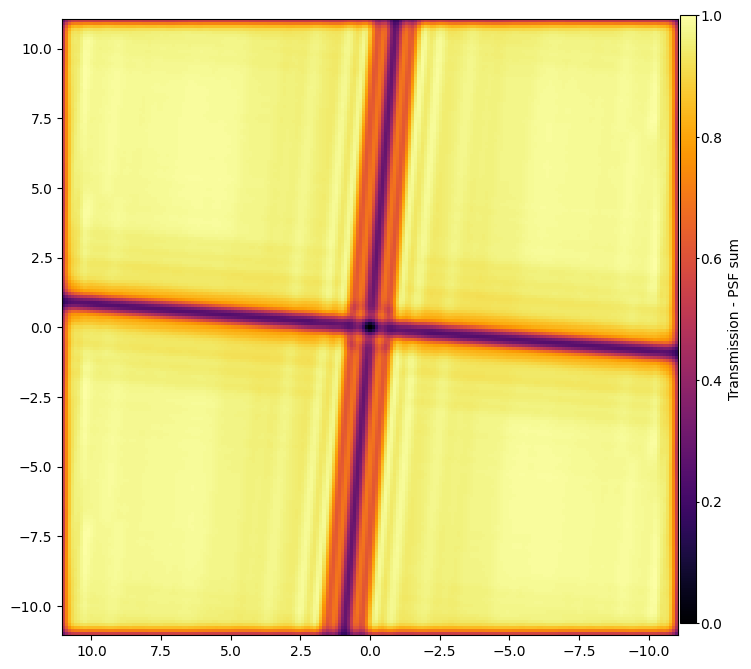

facteur de correction a F1550C :  2.0460859803162292


In [5]:
path_sim  = '/home/cperrot/Work/raw/JWST/STPSF/F1550C_PSF/'
path_save = '/home/cperrot/Work/projet/JWST/Target/Calib/transmission/'
filename  = 'F1550C_PSF_cube_save'
psfname   = 'F1550C_PSF_PSF_without_coro'
filt      = 'F1550C'

#constant
coef_dr   = 1.5
cst = Constantes(0.110, filt, 4.83544897)
cst.dr = coef_dr*cst.lam/6.5*180.*3600./np.pi/cst.pixscale # taille en pixel de COEF_DR lambda/D


out_f_co, out_max_psf, out_sum_psf, mask_map = coro_attenuation_measure(path_sim, path_save)
coro_attenuation_plot(out_max_psf, out_sum_psf, path_save)
fact_corr = correction_factor_open_phot(path_sim, psfname, out_f_co)
print("facteur de correction a "+filt+" : ", fact_corr)

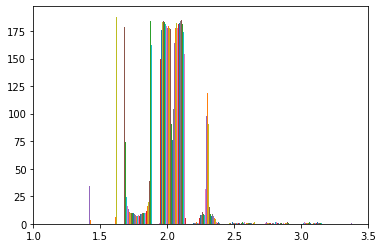

2.0751903

In [8]:
plt.hist(out_f_co[:], 70)
plt.xlim([1,3.5])
plt.show()
np.median(out_f_co)